# Predicting Poor-Fitting Rentals at Rent the Runway
**IS 4487 Final Project · Fall 2026**

**Team:** Gabrielle Jensen · [Teammate 2] · [Teammate 3]

🎥 **Video presentation:** [add YouTube link here]

---

## 1. Project Overview

Rent the Runway (RTR) rents designer clothing by subscription. Revenue has grown, but the company is still not profitable. When a rental doesn't fit, RTR pays for two-way shipping and cleaning and gets nothing for it, and the customer is more likely to cancel.

**Goal:** Use customer measurements and item details to predict whether a rental will fit poorly *before it ships*. We compare three classification models and pick the one that catches the most poor fits.

## 2. Business Problem & Context

### The organization
> 🔧 TODO: 2–3 sentences on RTR (founded 2009, business model, subscriber count from the latest 10-Q, with citation).

### The business challenge
> 🔧 TODO: Explain how poor fit drives costs (return shipping, cleaning, a lost rental slot) and churn. Use fulfillment-cost figures from the 10-K if you can.

### Why it matters
> 🔧 TODO: Business impact. For example: if X% of rentals fit poorly, each one costs about $Y in avoidable fulfillment.

### Industry & market factors
> 🔧 TODO: High return rates in online apparel, competition from resale and fast fashion, the cost of reverse logistics.

## 3. Data Sources & References

### Primary dataset: Rent the Runway Clothing Fit Data
- **Source:** UCSD McAuley Lab, https://cseweb.ucsd.edu/~jmcauley/datasets.html#clothing_fit
- **Contents:** 192,544 rental transactions from 105,508 customers across 5,850 items. Each row is one customer's rental of one item, with their self-reported fit feedback.

| Column | Description |
|---|---|
| `fit` | Customer feedback: **fit**, **small**, or **large** (our target) |
| `user_id`, `item_id` | Customer and item IDs |
| `bust size`, `weight`, `height`, `age`, `body type` | Customer measurements and profile |
| `size` | Size rented |
| `category` | Item type (dress, gown, sheath, romper…) |
| `rented for` | Occasion (wedding, party, work…) |
| `rating`, `review_text`, `review_summary`, `review_date` | Review written *after* the rental |

### Supporting source: RTR SEC filings and quarterly results
- https://investors.renttherunway.com/news-releases. Used for business context (subscribers, revenue, fulfillment costs).

### References
1. Misra, R., Wan, M., & McAuley, J. (2018). *Decomposing fit semantics for product size recommendation in metric spaces.* RecSys '18. (Dataset source)
2. > 🔧 TODO: RTR 10-K or 10-Q (company source)
3. > 🔧 TODO: Independent news article on RTR's financial performance (Reuters / CNBC / Retail Dive)

## 4. Data Acquisition & Loading

### Import libraries
We use pandas for data handling and matplotlib/seaborn for charts. We also set one chart style here so every chart in the notebook looks consistent.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# One consistent style for all charts
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (9, 5)

### Load the data
The file is gzipped JSON with **one record per line**, so we use `lines=True`. Pandas downloads and unzips it straight from the UCSD link, so no manual download is needed.

In [2]:
url = 'https://mcauleylab.ucsd.edu/public_datasets/data/renttherunway/renttherunway_final_data.json.gz'

df = pd.read_json(url, lines=True, compression='gzip')
df.shape

(192544, 15)

## 5. Data Exploration (EDA)

### Initial inspection

In [3]:
df.head()

,fit,user_id,bust size,item_id,weight,rating,rented for,review_text,body type,review_summary,category,height,size,age,review_date
0,fit,420272,34d,2260466,137lbs,10.0,vacation,An adorable romper! Belt and zipper were a lit...,hourglass,So many compliments!,romper,"5' 8""",14,28.0,"April 20, 2016"
1,fit,273551,34b,153475,132lbs,10.0,other,I rented this dress for a photo shoot. The the...,straight & narrow,I felt so glamourous!!!,gown,"5' 6""",12,36.0,"June 18, 2013"
2,fit,360448,NaN,1063761,NaN,10.0,party,This hugged in all the right places! It was a ...,NaN,It was a great time to celebrate the (almost) ...,sheath,"5' 4""",4,116.0,"December 14, 2015"
3,fit,909926,34c,126335,135lbs,8.0,formal affair,I rented this for my company's black tie award...,pear,Dress arrived on time and in perfect condition.,dress,"5' 5""",8,34.0,"February 12, 2014"
4,fit,151944,34b,616682,145lbs,10.0,wedding,I have always been petite in my upper body and...,athletic,Was in love with this dress !!!,gown,"5' 9""",12,27.0,"September 26, 2016"


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 192544 entries, 0 to 192543
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   fit             192544 non-null  str    
 1   user_id         192544 non-null  int64  
 2   bust size       174133 non-null  str    
 3   item_id         192544 non-null  int64  
 4   weight          162562 non-null  str    
 5   rating          192462 non-null  float64
 6   rented for      192534 non-null  str    
 7   review_text     192544 non-null  str    
 8   body type       177907 non-null  str    
 9   review_summary  192544 non-null  str    
 10  category        192544 non-null  str    
 11  height          191867 non-null  str    
 12  size            192544 non-null  int64  
 13  age             191584 non-null  float64
 14  review_date     192544 non-null  str    
dtypes: float64(2), int64(3), str(10)
memory usage: 22.0 MB


**What we notice:**
- `weight` and `height` are stored as **text** (`"137lbs"`, `5' 8"`), so we have to convert them to numbers.
- `bust size` combines two things, the band number and the cup letter (`"34d"`).
- Several columns have missing values (fewer non-null counts than 192,544 rows).

### Summary statistics

In [5]:
df.describe()

,user_id,item_id,rating,size,age
count,192544.000000,1.925440e+05,192462.000000,192544.000000,191584.000000
mean,499494.100149,1.045684e+06,9.092371,12.245175,33.871017
std,289059.719328,8.053148e+05,1.430044,8.494877,8.058083
min,9.000000,1.233730e+05,2.000000,0.000000,0.000000
25%,250654.250000,1.950760e+05,8.000000,8.000000,29.000000
50%,499419.000000,9.483960e+05,10.000000,12.000000,32.000000
75%,750974.000000,1.678888e+06,10.000000,16.000000,37.000000
max,999997.000000,2.966087e+06,10.000000,58.000000,117.000000


> 🔧 TODO: Interpret this. For example, `age` has a min of 0 and a max of 117, which can't be real, so we'll filter it in cleaning.

### Target variable: how often do rentals fit?

In [6]:
df['fit'].value_counts(normalize=True).round(3)

fit
fit      0.738
small    0.134
large    0.128
Name: proportion, dtype: float64

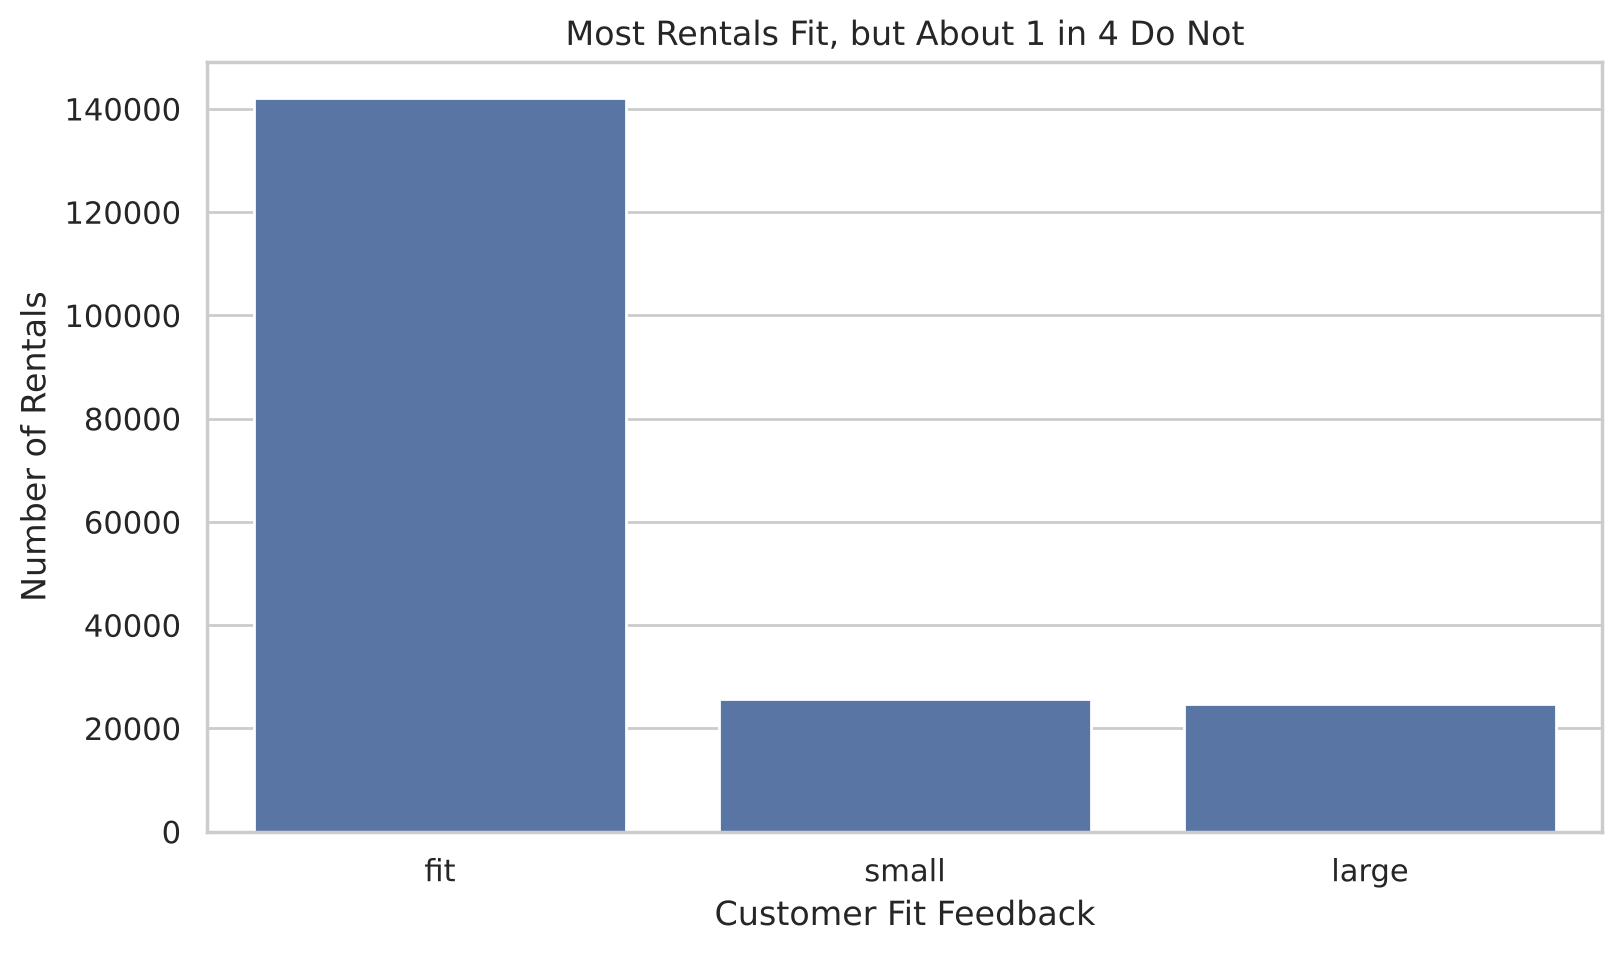

In [7]:
sns.countplot(data=df, x='fit', order=['fit', 'small', 'large'])
plt.title('Most Rentals Fit, but About 1 in 4 Do Not')
plt.xlabel('Customer Fit Feedback')
plt.ylabel('Number of Rentals')
plt.show()

**Key finding:** About **74%** of rentals fit, while **13%** run small and **13%** run large. The classes are **imbalanced**, so a model that always guesses "fit" would be 74% accurate and still useless. We'll keep this in mind when we choose evaluation metrics.

### Missing values

In [8]:
df.isna().sum().sort_values(ascending=False)

weight            29982
bust size         18411
body type         14637
age                 960
height              677
rating               82
rented for           10
item_id               0
user_id               0
fit                   0
review_text           0
category              0
review_summary        0
size                  0
review_date           0
dtype: int64

> 🔧 TODO: Note which columns need handling (`weight`, `bust size`, `body type` have the most missing values).

### Poor-fit rate by occasion
We add a temporary yes/no column for poor fit (small or large) so we can compare groups.

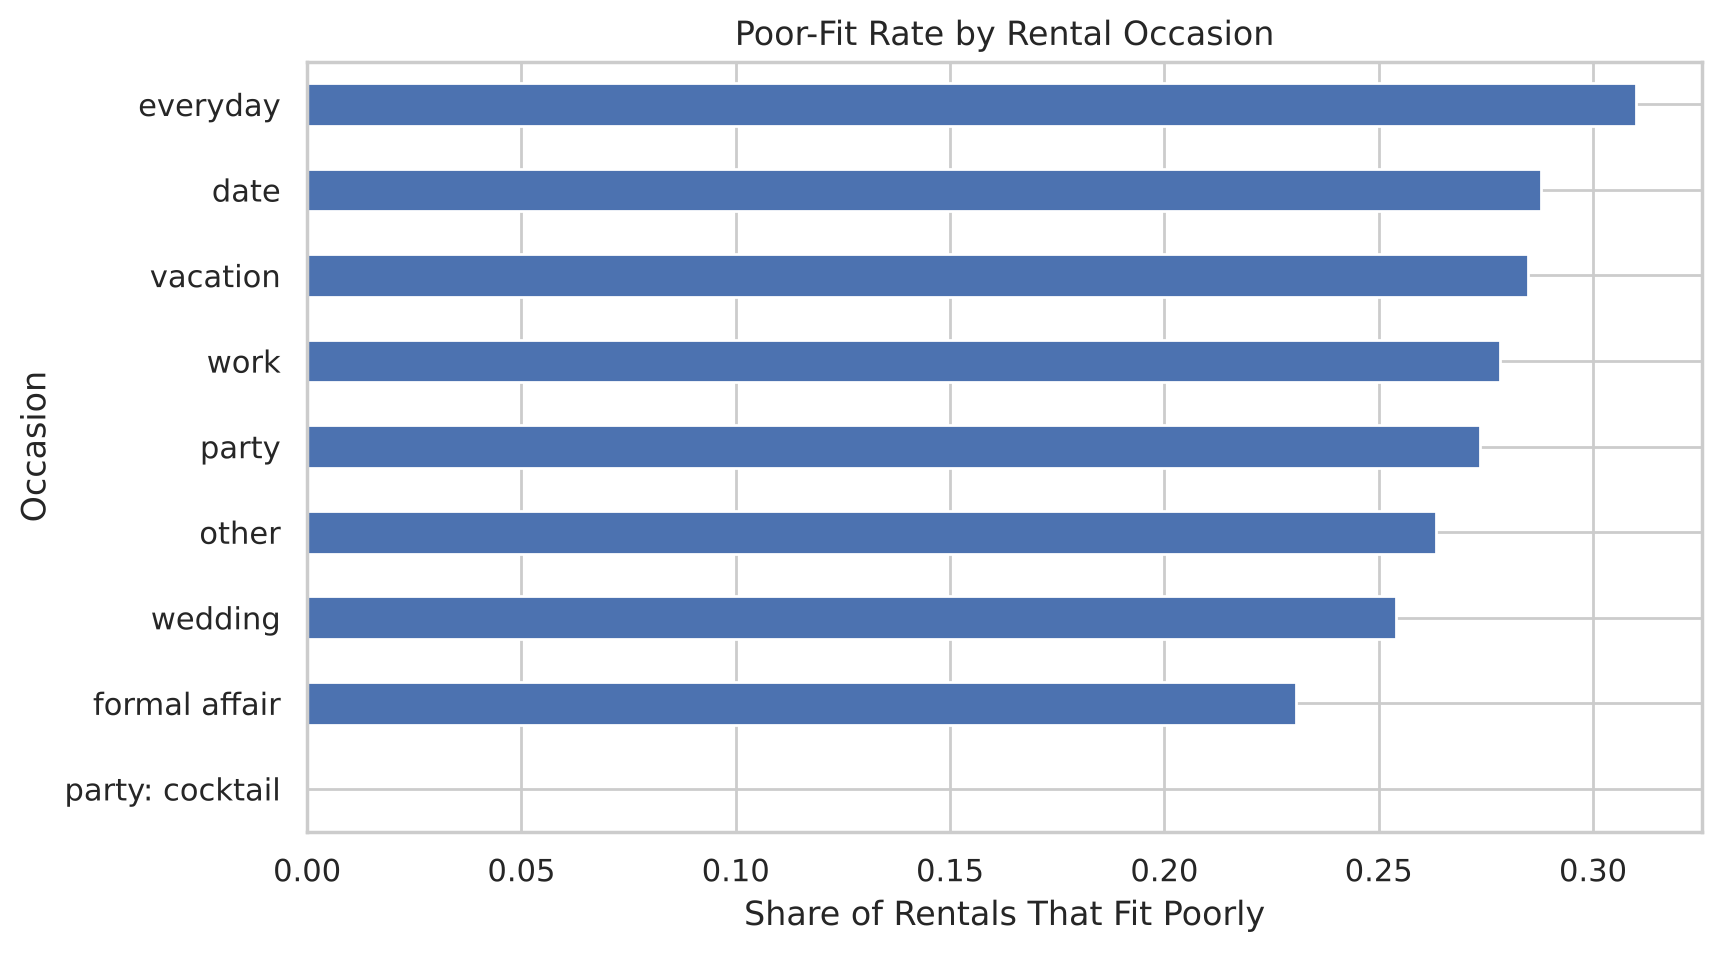

In [9]:
df['poor_fit'] = (df['fit'] != 'fit').astype(int)

occasion = df.groupby('rented for')['poor_fit'].mean().sort_values()
occasion.plot(kind='barh')
plt.title('Poor-Fit Rate by Rental Occasion')
plt.xlabel('Share of Rentals That Fit Poorly')
plt.ylabel('Occasion')
plt.show()

> 🔧 TODO: Interpret. Which occasions have the highest poor-fit rate? Why might that be?

### Poor-fit rate by clothing category (10 most-rented)

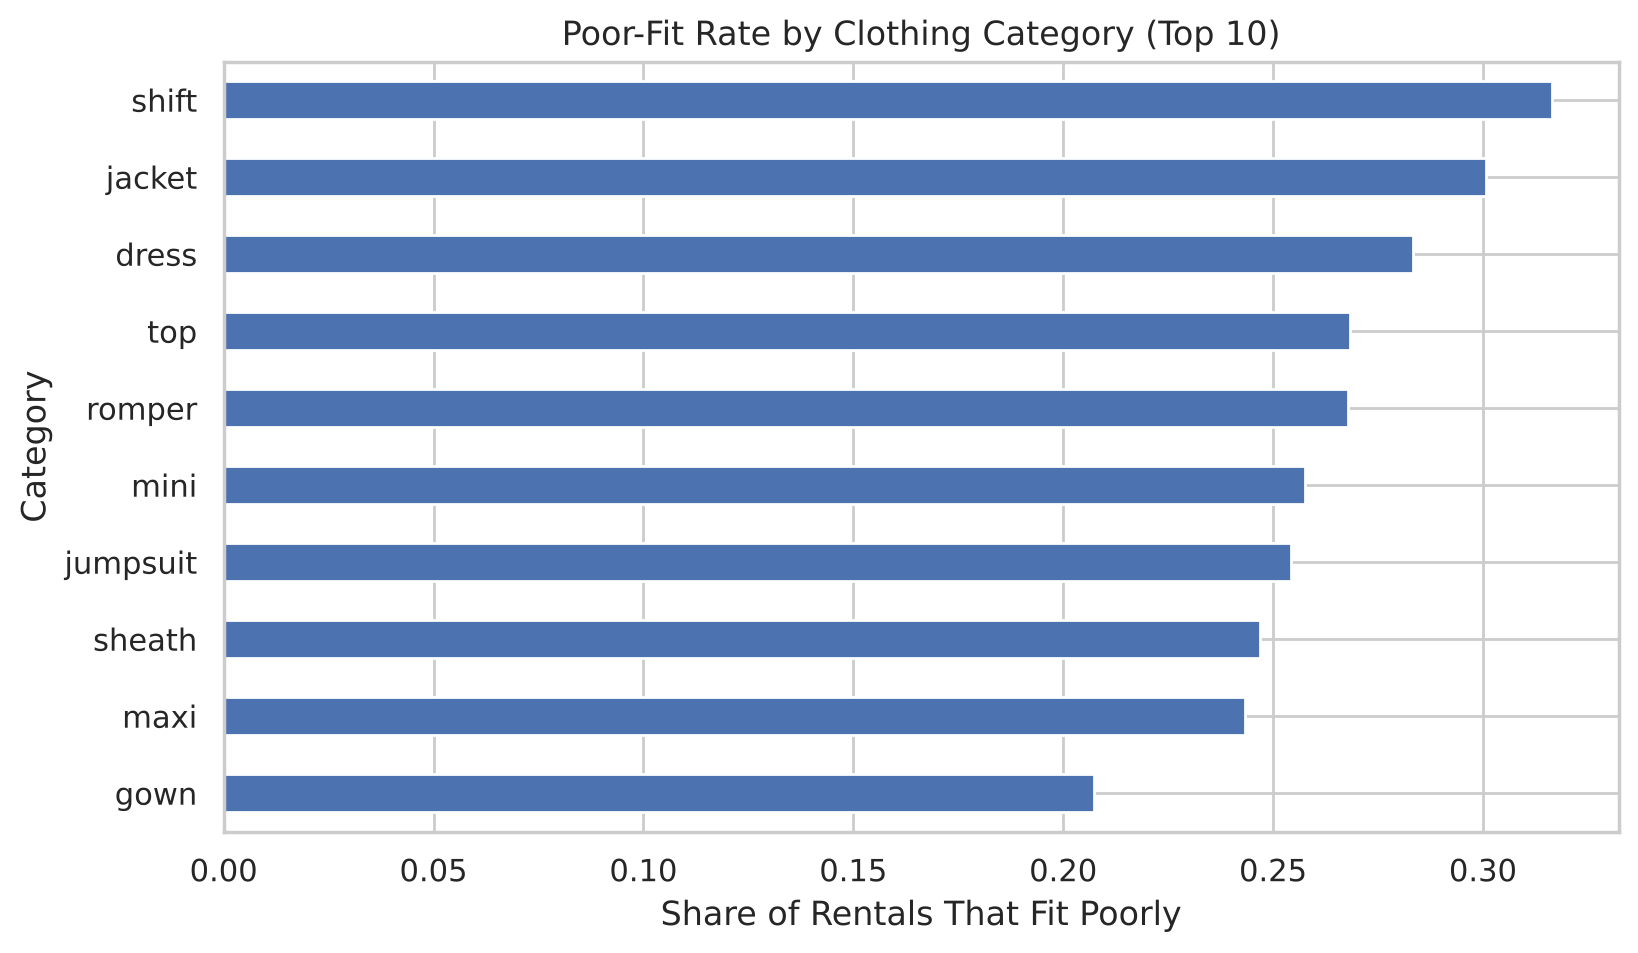

In [10]:
top10 = df['category'].value_counts().head(10).index

cat_fit = df[df['category'].isin(top10)].groupby('category')['poor_fit'].mean().sort_values()
cat_fit.plot(kind='barh')
plt.title('Poor-Fit Rate by Clothing Category (Top 10)')
plt.xlabel('Share of Rentals That Fit Poorly')
plt.ylabel('Category')
plt.show()

> 🔧 TODO: Interpret.

### Potential data issues to fix in cleaning
| Issue | Column(s) | Plan |
|---|---|---|
| Stored as text | `weight`, `height` | Convert to numbers (lbs, inches) |
| Two values in one column | `bust size` | Split into band and cup |
| Impossible values | `age` (0, 117) | Keep ages 18–75 |
| Missing values | `weight`, `bust size`, `body type`, `age`, `height` | Fill or drop (see Section 6) |
| Typo category | `rented for` = `"party: cocktail"` (1 row) | Merge into `party` |
| Too many categories | `category` (68 values) | Group rare ones into `other` |
| **Data leakage** ⚠️ | `rating`, `review_text`, `review_summary`, `review_date` | Drop. These are written *after* the rental, so RTR wouldn't have them at prediction time |

## 6. Data Cleaning & Preprocessing
> 🔧 TODO (baby steps, one short code cell each):
> 1. Define target: `poor_fit` = 1 if small/large, 0 if fit
> 2. Drop leakage + ID columns
> 3. Convert `weight` and `height` to numbers
> 4. Split `bust size` into band + cup
> 5. Filter `age` outliers
> 6. Handle missing values
> 7. Fix `rented for` typo; group rare `category` values
> 8. Feature engineering (e.g., BMI)
> 9. One-hot encode categoricals
> 10. Train/test split (80/20, `stratify=y`) and scale

## 7. Modeling Approach
> 🔧 TODO: Why each model was chosen (e.g., Logistic Regression, Decision Tree / Random Forest, KNN), how we handle class imbalance, and the cross-validation approach.

## 8. Model Implementation
> 🔧 TODO: One subsection per model: baseline fit → hyperparameter tuning (GridSearchCV) → final settings table.

## 9. Model Evaluation
> 🔧 TODO: Recall, precision, F1, ROC-AUC, and a confusion matrix per model. Add a comparison table and chart, then interpret in business terms.

## 10. Conclusions & Recommendations
> 🔧 TODO: Best model and why, business recommendations, next steps.

## 11. Final Descriptive Charts
> 🔧 TODO: 5–6 polished charts for the slides (same style as above).